# 05 · Final evaluation on the test set

**Goal:** give the honest final scores of the four models on stations they have never seen, say how sure we are of them, and find where the models fail and why.

| | |
|---|---|
| **Data** | test stations of the station split (`split == "test"`, 20% of rows), never used for training or tuning |
| **Models** | the four saved models from `04_models.ipynb`: mean baseline, Ridge, Random Forest, XGBoost |
| **Metrics** | MAE, RMSE, R² with 95% confidence intervals (bootstrap over stations) |
| **Extra** | paired model comparison, error analysis, a check on the year split, ablations, SHAP |
| **Before running** | `python -m src.train` must be final (it creates `models/*.joblib`) |

> **The test set is used once.** Section 1 predicts on it and saves `results/test_predictions.csv`; every later section reads that file. Do not use these results to change settings, features or models. If you retrain, delete `results/test_predictions.csv` so it is rebuilt (the notebook also does this automatically when the models are newer).

## 0. Setup

Imports, paths and constants. `N_BOOT` is the number of bootstrap resamples.

In [1]:
import os, sys, json
sys.path.append("..")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from src.features import (FEATURE_COLS, NUMERIC_COLS, CATEGORICAL_COLS, TARGET_COL,
                          get_xy, load_final_dataset, make_features)
from src.train import regression_metrics, make_pipeline, DATA_PATH, MODEL_DIR, RESULT_DIR

FIG_DIR = str(RESULT_DIR / "figures")
os.makedirs(FIG_DIR, exist_ok=True)
SEED, N_BOOT = 42, 2000

MODEL_FILES = {
    "Mean baseline": "dummy_regressor.joblib",
    "Ridge": "ridge_regression.joblib",
    "Random Forest": "random_forest.joblib",
    "XGBoost": "xgboost_regressor.joblib",
}
ORDER = list(MODEL_FILES)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/eval_{name}.png", bbox_inches="tight")
    plt.show()

## 1. Predict on the test set (once)

Load the data and the same three splits as in training. We check that **no station is shared** between train and test, so the test score really measures unseen stations.

In [2]:
df = make_features(load_final_dataset(str(DATA_PATH)))
X_train, y_train, X_val, y_val, X_test, y_test = get_xy(df, split_col="split")

train_sites = set(df.loc[X_train.index, "site_id"])
test_sites = set(df.loc[X_test.index, "site_id"])
assert not (train_sites & test_sites), "stations are shared between train and test!"
print(f"Train {len(X_train):,} rows | Test {len(X_test):,} rows from {len(test_sites):,} stations (none seen in training)")

Train 181,747 rows | Test 51,973 rows from 2,221 stations (none seen in training)


Predict with each saved model and save the predictions. If `results/test_predictions.csv` already exists and is newer than the models, it is reused, so the test set is not touched again. Then add the station, country and water type of each row.

In [3]:
TEST_PRED_PATH = RESULT_DIR / "test_predictions.csv"
stale = TEST_PRED_PATH.exists() and any(
    (MODEL_DIR / f).stat().st_mtime > TEST_PRED_PATH.stat().st_mtime for f in MODEL_FILES.values() if (MODEL_DIR / f).exists())

cached_ok = False
if TEST_PRED_PATH.exists() and not stale:
    cached = pd.read_csv(TEST_PRED_PATH)
    # The cache is only valid if it covers exactly the current test rows with the same true values.
    expect = pd.Series(y_test.to_numpy(), index=df.loc[X_test.index, "row_id"].to_numpy())
    one = cached[cached["model"] == cached["model"].iloc[0]].set_index("row_id")["y_true"]
    cached_ok = (set(cached["model"]) == set(MODEL_FILES) and len(one) == len(expect)
                 and np.allclose(one.reindex(expect.index).to_numpy(), expect.to_numpy()))
    if not cached_ok:
        print("Cached test predictions do not match the current split; recomputing.")

if cached_ok:
    preds = cached
    print("Loaded", TEST_PRED_PATH.name, "(already computed, matches the current test set)")
else:
    missing = [f for f in MODEL_FILES.values() if not (MODEL_DIR / f).exists()]
    if missing:
        raise FileNotFoundError(f"Missing {missing}. Run `python -m src.train` first.")
    frames = []
    for name, f in MODEL_FILES.items():
        model = joblib.load(MODEL_DIR / f)
        frames.append(pd.DataFrame({"row_id": df.loc[X_test.index, "row_id"].to_numpy(), "model": name,
                                    "y_true": y_test.to_numpy(), "y_pred": model.predict(X_test)}))
    preds = pd.concat(frames, ignore_index=True)
    preds.to_csv(TEST_PRED_PATH, index=False)
    print("Predicted on the test set and saved", TEST_PRED_PATH.name)

meta = df[["row_id", "site_id", "country", "waterbody_type", "year"]]
preds = preds.merge(meta, on="row_id", how="left", validate="many_to_one")
assert preds["country"].notna().all()
print(f"{len(preds):,} prediction rows = {preds['model'].nunique()} models x {preds['row_id'].nunique():,} test rows")

Loaded test_predictions.csv (already computed, matches the current test set)
207,892 prediction rows = 4 models x 51,973 test rows


## 2. Test scores and the step from validation to test

MAE, RMSE and R² of every model on the test set, next to the validation scores from training. A big drop from validation to test would mean the settings were tuned too closely to the validation stations.

In [4]:
def point_metrics(p):
    m = regression_metrics(p["y_true"], p["y_pred"])
    return pd.Series({"MAE": m["mae"], "RMSE": m["rmse"], "R2": m["r2"]})

test_table = preds.groupby("model")[["y_true", "y_pred"]].apply(point_metrics).loc[ORDER]

name_map = {"DummyRegressor": "Mean baseline", "Ridge": "Ridge",
            "RandomForestRegressor": "Random Forest", "XGBRegressor": "XGBoost"}
val_saved = pd.read_csv(RESULT_DIR / "validation_metrics.csv")
val_saved["model"] = val_saved["model"].map(name_map)
val_saved = val_saved.set_index("model").loc[ORDER]

compare = pd.DataFrame({"val RMSE": val_saved["rmse"], "test RMSE": test_table["RMSE"],
                        "val R2": val_saved["r2"], "test R2": test_table["R2"]})
compare["R2 change (test - val)"] = compare["test R2"] - compare["val R2"]
display(test_table.round(4))
display(compare.round(4))
best_name = val_saved["rmse"].idxmin()      # chosen on VALIDATION, not on test
print("Best model on validation (used as the model to analyse below):", best_name)

,MAE,RMSE,R2
model,,,
Mean baseline,9.5701,13.1590,-0.0007
Ridge,8.3288,11.7327,0.2045
Random Forest,7.5979,11.1793,0.2778
XGBoost,7.5435,11.0585,0.2933


,val RMSE,test RMSE,val R2,test R2,R2 change (test - val)
model,,,,,
Mean baseline,13.9120,13.1590,-0.0054,-0.0007,0.0048
Ridge,12.2626,11.7327,0.2188,0.2045,-0.0143
Random Forest,11.2470,11.1793,0.3429,0.2778,-0.0651
XGBoost,11.2048,11.0585,0.3478,0.2933,-0.0545


Best model on validation (used as the model to analyse below): XGBoost


**What we see → What we do about it:** Compare each model's test R² with its validation R². Differences of a few hundredths are normal because the test stations are different stations. The baseline's R² on test should be close to 0 (it can be slightly negative, because the test mean differs from the training mean).

## 3. How sure are we? Bootstrap confidence intervals

The test set is one sample of stations, so every score has some luck in it. To measure that, we repeat the evaluation 2,000 times on **resampled stations** (stations drawn with replacement, all rows of a drawn station kept together). We resample stations, not rows, because rows of one station are not independent; resampling rows would give intervals that are too narrow.

The same resamples are used for all models, so differences between models can be compared fairly (section 4).

In [5]:
# Per-station sums for each model: n, sum y, sum y^2, sum |error|, sum error^2.
# These are enough to compute MAE, RMSE and R^2 of any resample of stations quickly.
e = preds["y_pred"] - preds["y_true"]
sums = pd.DataFrame({"site_id": preds["site_id"], "model": preds["model"], "n": 1.0,
                     "sy": preds["y_true"], "syy": preds["y_true"] ** 2, "sae": e.abs(), "sse": e ** 2})
agg = sums.groupby(["model", "site_id"]).sum()

stations = np.array(sorted(preds["site_id"].unique()))
S = len(stations)
A = {m: agg.loc[m].reindex(stations).fillna(0.0).to_numpy() for m in ORDER}    # S x 5 per model

rng = np.random.default_rng(SEED)
counts = rng.multinomial(S, np.full(S, 1.0 / S), size=N_BOOT)                  # N_BOOT x S: how often each station is drawn

def metrics_from_totals(tot):
    n, sy, syy, sae, sse = (tot[..., i] for i in range(5))
    sst = syy - sy ** 2 / n
    return {"MAE": sae / n, "RMSE": np.sqrt(sse / n), "R2": 1.0 - sse / sst}

boot = {m: metrics_from_totals(counts @ A[m]) for m in ORDER}                  # N_BOOT values per metric
point = {m: metrics_from_totals(A[m].sum(axis=0)) for m in ORDER}              # the real test score
print(f"{S:,} test stations, {N_BOOT:,} bootstrap resamples")

2,221 test stations, 2,000 bootstrap resamples


Build the main results table: the real test score with its 95% interval for each model. This is the table for the report.

In [6]:
rows = []
for m in ORDER:
    r = {"model": m}
    for k in ["MAE", "RMSE", "R2"]:
        lo, hi = np.percentile(boot[m][k], [2.5, 97.5])
        r[k] = float(point[m][k]); r[k + " lo"] = float(lo); r[k + " hi"] = float(hi)
    rows.append(r)
final = pd.DataFrame(rows).set_index("model")
final.to_csv(RESULT_DIR / "final_results.csv")

pretty = pd.DataFrame({k: [f"{final.loc[m, k]:.3f}  [{final.loc[m, k + ' lo']:.3f}, {final.loc[m, k + ' hi']:.3f}]" for m in ORDER]
                       for k in ["MAE", "RMSE", "R2"]}, index=ORDER)
display(pretty)
print("Saved results/final_results.csv. Format: score [95% interval]")

,MAE,RMSE,R2
Mean baseline,"9.570 [9.070, 10.134]","13.159 [12.376, 13.996]","-0.001 [-0.009, -0.000]"
Ridge,"8.329 [7.883, 8.820]","11.733 [11.067, 12.428]","0.205 [0.174, 0.233]"
Random Forest,"7.598 [7.157, 8.094]","11.179 [10.513, 11.935]","0.278 [0.230, 0.324]"
XGBoost,"7.543 [7.103, 8.041]","11.058 [10.384, 11.816]","0.293 [0.246, 0.340]"


Saved results/final_results.csv. Format: score [95% interval]


A chart of the same table. Intervals that do not overlap clearly separate two models; overlapping intervals do not prove they are equal (see the paired test below).

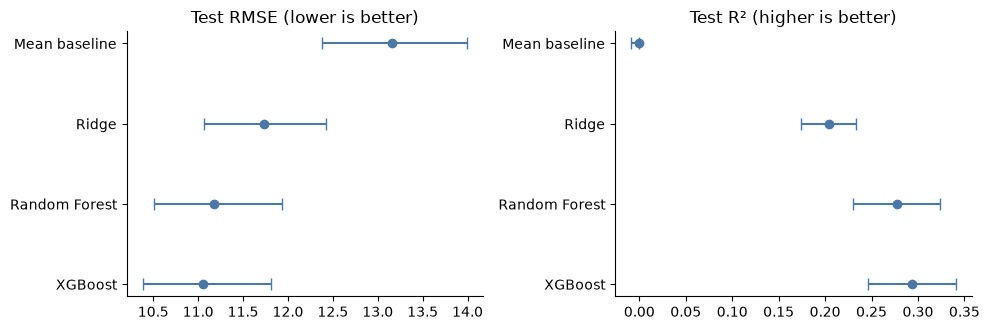

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, k, title in zip(axes, ["RMSE", "R2"], ["Test RMSE (lower is better)", "Test R² (higher is better)"]):
    y = np.arange(len(ORDER))
    ax.errorbar(final[k], y, xerr=[final[k] - final[k + " lo"], final[k + " hi"] - final[k]], fmt="o", color="#4c78a8", capsize=4)
    ax.set_yticks(y); ax.set_yticklabels(ORDER); ax.invert_yaxis(); ax.set_title(title)
save("ci")

**What we see → What we do about it:** Look at the width of the intervals. They show how much the score would move with a different sample of stations. Report scores as value with interval, never as a bare number.

## 4. Is one model really better? Paired comparison
For two models on the **same** resampled stations, take the difference of their RMSE. If the 95% interval of the difference excludes 0, the difference is not just luck. `P(first is better)` is the share of resamples in which the first model had the lower RMSE.

In [8]:
pairs = [("XGBoost", "Random Forest"), ("XGBoost", "Ridge"), ("Random Forest", "Ridge"),
         ("XGBoost", "Mean baseline"), ("Random Forest", "Mean baseline"), ("Ridge", "Mean baseline")]
rows = []
for a, b in pairs:
    d_rmse = boot[a]["RMSE"] - boot[b]["RMSE"]
    d_r2 = boot[a]["R2"] - boot[b]["R2"]
    lo, hi = np.percentile(d_rmse, [2.5, 97.5])
    rows.append({"first": a, "second": b,
                 "RMSE difference (first - second)": point[a]["RMSE"] - point[b]["RMSE"],
                 "95% interval": f"[{lo:.3f}, {hi:.3f}]",
                 "P(first has lower RMSE)": float((d_rmse < 0).mean()),
                 "R2 difference": point[a]["R2"] - point[b]["R2"],
                 "clearly different?": "yes" if (lo > 0 or hi < 0) else "no"})
paired = pd.DataFrame(rows)
display(paired.round(4))

,first,second,RMSE difference (first - second),95% interval,P(first has lower RMSE),R2 difference,clearly different?
0,XGBoost,Random Forest,-0.1208,"[-0.186, -0.059]",1.0,0.0155,yes
1,XGBoost,Ridge,-0.6742,"[-0.919, -0.429]",1.0,0.0888,yes
2,Random Forest,Ridge,-0.5534,"[-0.804, -0.311]",1.0,0.0733,yes
3,XGBoost,Mean baseline,-2.1006,"[-2.526, -1.709]",1.0,0.2940,yes
4,Random Forest,Mean baseline,-1.9798,"[-2.401, -1.582]",1.0,0.2784,yes
5,Ridge,Mean baseline,-1.4264,"[-1.688, -1.171]",1.0,0.2052,yes


**What we see → What we do about it:** A negative RMSE difference means the first model is better. If the interval of XGBoost vs Random Forest contains 0, say that the two tree models are statistically tied and do not claim a winner. Both should be clearly better than Ridge and the baseline; if so, the non-linear tree models are justified.

## 5. Where does the model fail? Error analysis

We analyse the model that was best on **validation** (chosen before seeing the test set). Positive error means the model predicted a better quality than the true value.

In [9]:
pb = preds[preds["model"] == best_name][["row_id", "site_id", "country", "waterbody_type", "year", "y_true", "y_pred"]].copy()
pz = preds[preds["model"] == "Mean baseline"][["row_id", "y_pred"]].rename(columns={"y_pred": "y_base"})
pb = pb.merge(pz, on="row_id", validate="one_to_one")
pb["error"] = pb["y_pred"] - pb["y_true"]
pb["abs_error"] = pb["error"].abs()
pb["abs_error_base"] = (pb["y_base"] - pb["y_true"]).abs()

def r2(y, p):
    sst = ((y - y.mean()) ** 2).sum()
    return float(1 - ((y - p) ** 2).sum() / sst) if len(y) > 1 and sst > 0 else float("nan")

def group_table(col):
    rows = []
    for key, g in pb.groupby(col):
        rows.append({col: key, "rows": len(g), "stations": g["site_id"].nunique(),
                     "MAE": g["abs_error"].mean(), "baseline MAE": g["abs_error_base"].mean(),
                     "MAE gain vs baseline %": 100 * (1 - g["abs_error"].mean() / g["abs_error_base"].mean()),
                     "RMSE": float(np.sqrt((g["error"] ** 2).mean())), "R2": r2(g["y_true"], g["y_pred"]),
                     "mean error (bias)": g["error"].mean()})
    return pd.DataFrame(rows).set_index(col)
print("Model analysed:", best_name)

Model analysed: XGBoost


### 5.1 By country
The overall score hides large differences between countries. `MAE gain vs baseline` says how much the model helps over always predicting the average. A negative R² inside a country means the model is worse than that country's own average.

,rows,stations,MAE,baseline MAE,MAE gain vs baseline %,RMSE,R2,mean error (bias)
country,,,,,,,,
Canada,554,388,7.629,8.150,6.391,11.044,0.080,-0.899
England,36396,980,9.254,9.858,6.121,12.391,0.194,-0.128
Ireland,14443,832,3.296,8.908,63.003,6.676,0.026,-0.190
USA,580,21,5.877,9.354,37.167,9.816,0.156,1.901


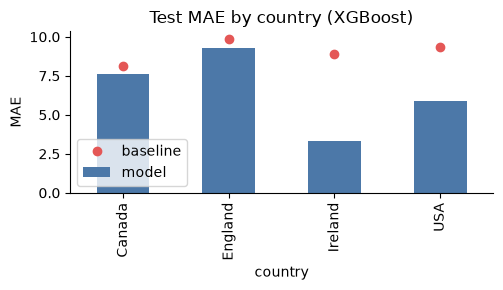

In [10]:
by_country = group_table("country")
display(by_country.round(3))
by_country["MAE"].plot.bar(figsize=(5, 3), color="#4c78a8", label="model")
plt.plot(range(len(by_country)), by_country["baseline MAE"].to_numpy(), "o", color="#e45756", label="baseline")
plt.ylabel("MAE"); plt.title(f"Test MAE by country ({best_name})"); plt.legend()
save("by_country")

**What we see → What we do about it:** Check which countries have many rows and which few. England is the biggest group, so it drives the overall score; small groups (USA, Canada) have wide uncertainty. Also compare each country's R² with the overall R²: countries such as Ireland and the USA are almost always near 100, so inside them there is little left to explain and R² is low even when MAE is small. Part of the overall R² comes from the model knowing that the countries have different average quality. State all of this in the report.

### 5.2 By water type

In [11]:
by_type = group_table("waterbody_type")
display(by_type.round(3))

,rows,stations,MAE,baseline MAE,MAE gain vs baseline %,RMSE,R2,mean error (bias)
waterbody_type,,,,,,,,
Canal,1098,22,9.160,10.583,13.445,11.693,0.287,-2.027
Estuarine/Transitional,1028,55,8.867,10.783,17.766,12.663,0.247,1.585
Lake,1336,106,5.140,9.905,48.106,9.721,0.216,-0.630
Marine/Coastal,1013,55,13.367,14.918,10.397,16.898,0.247,-0.310
River,47498,2034,7.421,9.397,21.029,10.883,0.289,-0.106


**What we see → What we do about it:** Look for water types where the model barely beats the baseline. Those are the types where the inputs (dissolved oxygen, pH, temperature) carry little information about the index.

### 5.3 By true quality level
The index is capped at 100 and 44% of rows are exactly 100. We split the test rows by the true value and look at the error and the bias (mean of predicted minus true) in each band.

,rows,MAE,bias,mean_true,mean_pred,share of rows %
band,,,,,,
< 60 (poor),2719,30.983,30.983,51.353,82.337,5.232
60 to 80,6032,12.523,12.150,71.274,83.424,11.606
80 to 95,20502,5.192,-1.898,89.596,87.698,39.447
= 100,22720,5.539,-5.520,100.000,94.480,43.715


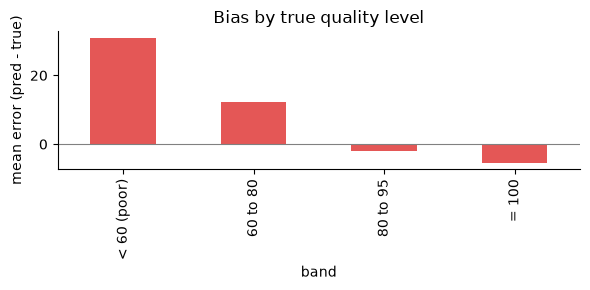

In [12]:
bands = [-0.1, 60, 80, 95, 100, 100.001]
labels = ["< 60 (poor)", "60 to 80", "80 to 95", "95 to < 100", "= 100"]
pb["band"] = pd.cut(pb["y_true"], bins=bands, labels=labels, right=False)
by_band = pb.groupby("band", observed=True).agg(rows=("y_true", "size"), MAE=("abs_error", "mean"),
                                                 bias=("error", "mean"), mean_true=("y_true", "mean"), mean_pred=("y_pred", "mean"))
by_band["share of rows %"] = 100 * by_band["rows"] / by_band["rows"].sum()
display(by_band.round(3))
ax = by_band["bias"].plot.bar(figsize=(6, 3), color="#e45756"); ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("mean error (pred - true)"); ax.set_title("Bias by true quality level")
save("bias_by_band")

**What we see → What we do about it:** Expect a positive bias for poor water (model too optimistic) and a small negative bias at 100 (it cannot reach the cap). This pattern is called regression to the mean. It comes from the held-out parameters: without them the model cannot tell when water is really poor. This is the honest limitation to state.

### 5.4 Residuals
Residual = predicted minus true. A good model has residuals centred on 0 with no pattern against the true value.

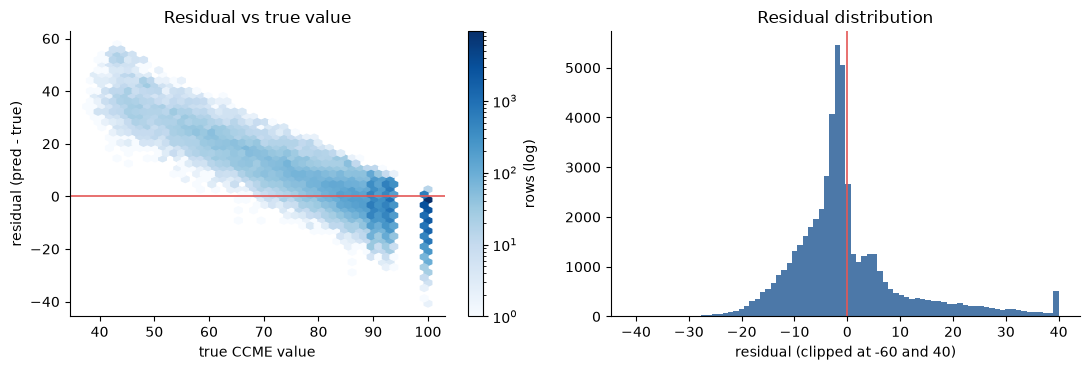

Mean residual -0.13, median -1.85, std 11.06


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
hb = axes[0].hexbin(pb["y_true"], pb["error"], gridsize=45, bins="log", cmap="Blues", mincnt=1)
axes[0].axhline(0, color="#e45756", lw=1.2)
axes[0].set_xlabel("true CCME value"); axes[0].set_ylabel("residual (pred - true)"); axes[0].set_title("Residual vs true value")
fig.colorbar(hb, ax=axes[0], label="rows (log)")
axes[1].hist(pb["error"].clip(-60, 40), bins=80, color="#4c78a8")
axes[1].axvline(0, color="#e45756", lw=1.2); axes[1].set_xlabel("residual (clipped at -60 and 40)"); axes[1].set_title("Residual distribution")
save("residuals")
print(f"Mean residual {pb['error'].mean():.2f}, median {pb['error'].median():.2f}, std {pb['error'].std():.2f}")

**What we see → What we do about it:** A downward slope against the true value shows the squeeze towards the mean. A long left tail means a few poor samples were predicted as good, which would be the costly mistake in practice.

### 5.5 Hardest stations
Stations with the largest average error (at least 5 test rows).

In [14]:
st = pb.groupby("site_id").agg(country=("country", "first"), rows=("y_true", "size"), mean_true=("y_true", "mean"),
                               mean_pred=("y_pred", "mean"), MAE=("abs_error", "mean"))
display(st[st["rows"] >= 5].sort_values("MAE", ascending=False).head(10).round(2))

,country,rows,mean_true,mean_pred,MAE
site_id,,,,,
England|BSC CORBY MANHOLE ADJ NORTHERN STREAM,England,153,49.40,90.73,41.35
England|NORTHFLEET STW,England,11,43.85,79.74,35.89
England|HELPSTON LODGE FARM B/H HA1,England,27,47.07,82.84,35.78
England|THE SKELL AT SKELBROOKE,England,54,47.64,79.97,32.33
England|D/S MANNINGS HEATH STW,England,67,53.49,83.68,31.84
England|SHOTTON BECK AT SHOTTON FARM,England,93,61.62,92.52,30.90
England|HOUSELOP BECK TRIB 100M D/S TOW LAW STW,England,29,59.04,85.33,27.01
England|FURZEFIELD LEISURE CENTRE B/H,England,18,62.40,88.96,26.56
England|M42 SERVICE AREA INTERCEPT WETLAND R/OFF,England,6,65.00,91.15,26.15


**What we see → What we do about it:** If the worst stations are all poor-quality sites predicted as good, that matches the bias above. A few stations cannot be fixed by tuning; they show what the inputs cannot capture.

## 6. Second check: does it work on future years? (year split)

The main split asks "does it work at new stations?". The brief also allows a time-separated split, so we test the second question: train on years up to 2015, tune on 2016–2017, test on 2018 onwards (`split_time`). The saved models were trained on the station split, so they cannot be used here (their training data contains some of the year-test rows). We refit the four models on the year split with the **same settings** chosen earlier (`results/training_config.json`). Takes a few minutes.

In [15]:
RUN_YEAR_SPLIT = True

if RUN_YEAR_SPLIT:
    from sklearn.dummy import DummyRegressor
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.linear_model import Ridge
    from xgboost import XGBRegressor

    cfg = json.load(open(RESULT_DIR / "training_config.json"))["selected_parameters"]
    Xtr, ytr, Xva, yva, Xte, yte = get_xy(df, split_col="split_time")
    print(f"Year split: train {len(Xtr):,} | val {len(Xva):,} | test {len(Xte):,}")

    year_models = {
        "Mean baseline": DummyRegressor(strategy="mean"),
        "Ridge": make_pipeline(Ridge(**cfg["Ridge"]), scale=True),
        "Random Forest": make_pipeline(RandomForestRegressor(**cfg["RandomForestRegressor"], n_jobs=-1, random_state=SEED), scale=False),
        "XGBoost": make_pipeline(XGBRegressor(**cfg["XGBRegressor"], objective="reg:squarederror", subsample=0.8, colsample_bytree=0.8,
                                              reg_lambda=1.0, random_state=SEED, n_jobs=-1, tree_method="hist", verbosity=0), scale=False),
    }
    rows = []
    for name, model in year_models.items():
        model.fit(Xtr, ytr)
        m = regression_metrics(yte, model.predict(Xte))
        rows.append({"model": name, "year-split test MAE": m["mae"], "RMSE": m["rmse"], "R2": m["r2"]})
        print("done", name)
    year_table = pd.DataFrame(rows).set_index("model")
    year_table["station-split test R2"] = final["R2"]
    print("Note: the year-split test set (2018+) is a different population from the station-split test set, so compare\n"
          "models within a column, not across the two splits. The mean baseline is not ~0 here because the target shifted over time.\n"
          "Hyperparameters were tuned on the station-split validation set and reused here without retuning.")
    display(year_table.round(4))
    year_table.to_csv(RESULT_DIR / "year_split_results.csv")

Year split: train 185,094 | val 21,499 | test 53,181
done Mean baseline
done Ridge
done Random Forest
done XGBoost
Note: the year-split test set (2018+) is a different population from the station-split test set, so compare
models within a column, not across the two splits. The mean baseline is not ~0 here because the target shifted over time.


,year-split test MAE,RMSE,R2,station-split test R2
model,,,,
Mean baseline,9.1010,10.6930,-0.3377,-0.0007
Ridge,6.7382,8.7862,0.0969,0.2045
Random Forest,5.5957,8.3099,0.1921,0.2778
XGBoost,5.4488,8.0466,0.2425,0.2933


**What we see → What we do about it:** Compare the two R² columns. A year-split score close to the station-split score means the model holds up on future data as well as on new stations. A clearly lower year-split score would mean conditions change over time (for example different monitoring programmes after 2018). Note that stations repeat across the year-split sets, so this check is easier on the station side and harder on the time side.

## 7. How much is just "which country"? Ablations (on validation)

In `04_models.ipynb` the country was the strongest input. To see how much of the score depends on it, we refit XGBoost with some inputs removed and compare on the **validation** set (not the test set, so the test set stays untouched). The setting is the chosen XGBoost setting.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor

xgb_params = json.load(open(RESULT_DIR / "training_config.json"))["selected_parameters"]["XGBRegressor"]
HISTORY = [c for c in NUMERIC_COLS if "site_prev" in c or c == "days_since_prev"]

def fit_variant(num_cols, cat_cols):
    pre = ColumnTransformer([("num", SimpleImputer(strategy="median", add_indicator=True), num_cols),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
    model = Pipeline([("preprocessor", pre),
                      ("model", XGBRegressor(**xgb_params, objective="reg:squarederror", subsample=0.8, colsample_bytree=0.8,
                                             reg_lambda=1.0, random_state=SEED, n_jobs=-1, tree_method="hist", verbosity=0))])
    cols = num_cols + cat_cols
    model.fit(X_train[cols], y_train)
    return regression_metrics(y_val, model.predict(X_val[cols]))

no_hist = [c for c in NUMERIC_COLS if c not in HISTORY]
variants = {
    "all 14 inputs (chosen model)": (NUMERIC_COLS, CATEGORICAL_COLS),
    "without country": (NUMERIC_COLS, ["waterbody_type"]),
    "without station history": (no_hist, CATEGORICAL_COLS),
    "without country and history": (no_hist, ["waterbody_type"]),
}
rows = []
for name, (num, cat) in variants.items():
    m = fit_variant(num, cat)
    rows.append({"inputs": name, "val MAE": m["mae"], "val RMSE": m["rmse"], "val R2": m["r2"]})
    print("done:", name)
ablation = pd.DataFrame(rows).set_index("inputs")
display(ablation.round(4))
# Sanity check: the re-fitted chosen model should match the saved validation score from src/train.py.
saved_r2 = pd.read_csv(RESULT_DIR / "validation_metrics.csv").set_index("model").loc["XGBRegressor", "r2"]
diff = abs(ablation.iloc[0]["val R2"] - saved_r2)
print(f"Chosen-model row vs saved validation R2: difference {diff:.4f}")
assert diff < 0.002, "Ablation settings have drifted from src/train.py; update this cell."
ablation.to_csv(RESULT_DIR / "ablation_validation.csv")

done: all 14 inputs (chosen model)
done: without country
done: without station history
done: without country and history


,val MAE,val RMSE,val R2
inputs,,,
all 14 inputs (chosen model),7.7292,11.2048,0.3478
without country,8.3034,11.8226,0.2739
without station history,8.1023,11.8429,0.2714
without country and history,8.8307,12.7013,0.1620


Chosen-model row vs saved validation R2: difference 0.0000


**What we see → What we do about it:** The drop in R² when an input group is removed shows how much the model relies on it. If removing the country costs a lot, then part of our score is only knowing which country a sample comes from. If removing the history costs a lot, the model leans on the station's earlier readings. Either way, say it in the report; do not present the full score as pure water chemistry.

## 8. Why does the model predict what it predicts? SHAP

SHAP splits each prediction into contributions of the inputs: how many index points each input pushed the prediction up or down from the average prediction. For XGBoost the exact SHAP values come from the model itself (`pred_contribs`). We use a random sample of 3,000 test rows. SHAP shows what the **model** relies on, not what **causes** water quality.

In [17]:
import shap
import xgboost as xgb

xgb_pipe = joblib.load(MODEL_DIR / MODEL_FILES["XGBoost"])
pre, xgb_model = xgb_pipe.named_steps["preprocessor"], xgb_pipe.named_steps["model"]

rng = np.random.default_rng(SEED)
idx = np.sort(rng.choice(len(X_test), size=min(3000, len(X_test)), replace=False))
Xs = X_test.iloc[idx]
Xt = pre.transform(Xs)
Xt = Xt.toarray() if hasattr(Xt, "toarray") else np.asarray(Xt)
names = [n.replace("num__", "").replace("cat__", "") for n in pre.get_feature_names_out()]

contribs = xgb_model.get_booster().predict(xgb.DMatrix(Xt), pred_contribs=True)
sv, base_value = contribs[:, :-1], float(contribs[:, -1].mean())
print(f"{sv.shape[0]:,} rows x {sv.shape[1]} inputs; average prediction (base value) {base_value:.1f}")

3,000 rows x 30 inputs; average prediction (base value) 90.4


### 8.1 Which inputs matter most
Average absolute SHAP value per input (the size of its typical push on the prediction), and the beeswarm plot: each dot is one test row; the colour is the input's value, the position is the push on the prediction.

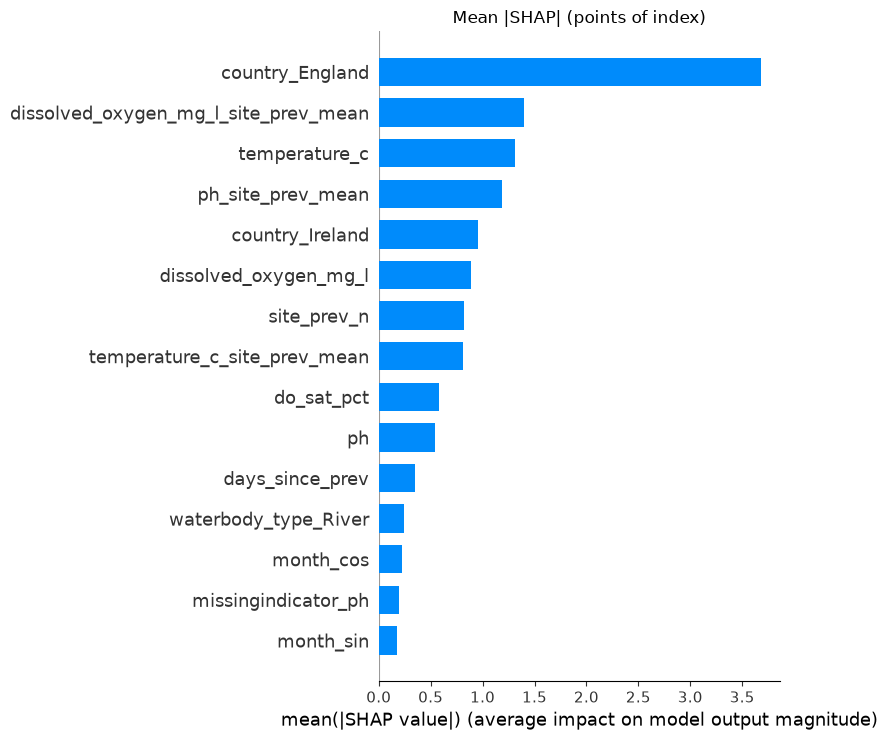

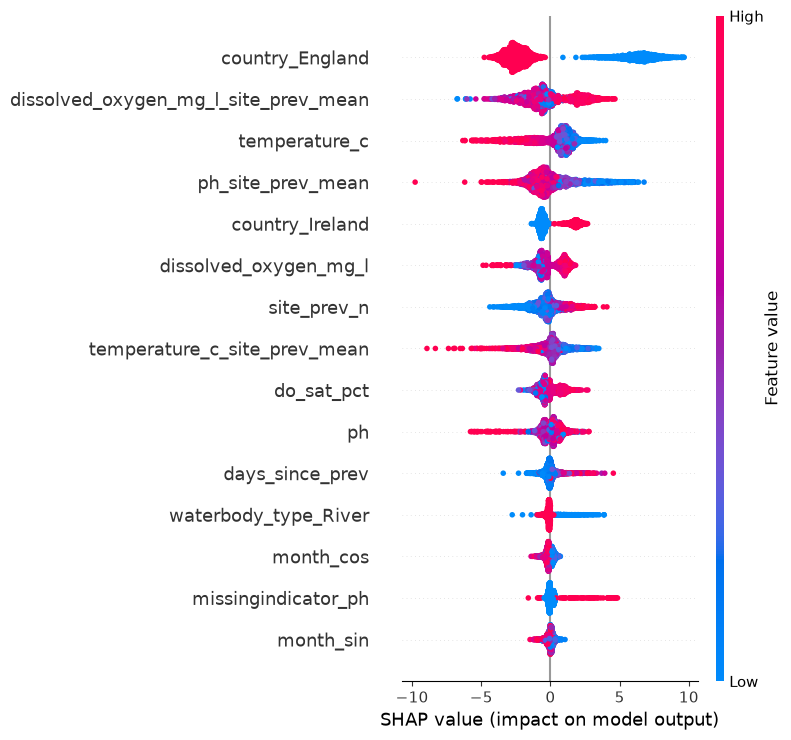

In [18]:
plt.figure()
shap.summary_plot(sv, Xt, feature_names=names, plot_type="bar", max_display=15, show=False)
plt.title("Mean |SHAP| (points of index)")
save("shap_bar")

plt.figure()
shap.summary_plot(sv, Xt, feature_names=names, max_display=15, show=False)
save("shap_beeswarm")

The one-hot columns split a single input into several bars (one per country, one per water type). Adding them up gives the importance of the whole input:

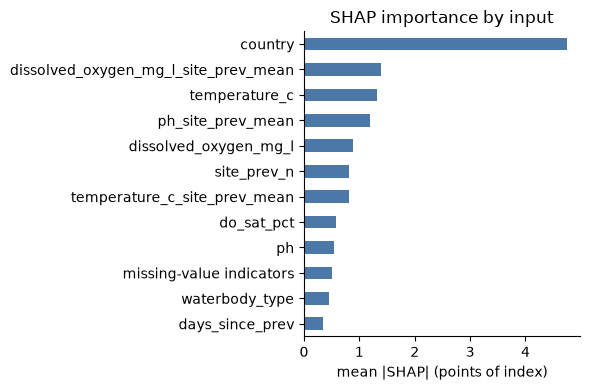

,mean |SHAP|
country,4.747
dissolved_oxygen_mg_l_site_prev_mean,1.396
temperature_c,1.316
ph_site_prev_mean,1.187
dissolved_oxygen_mg_l,0.889
site_prev_n,0.817
temperature_c_site_prev_mean,0.807
do_sat_pct,0.576
ph,0.542
missing-value indicators,0.499


In [19]:
def group_of(n):
    if n.startswith("country_"): return "country"
    if n.startswith("waterbody_type_"): return "waterbody_type"
    if n.startswith("missingindicator_"): return "missing-value indicators"
    return n
grouped = pd.Series(np.abs(sv).mean(axis=0), index=names).groupby(group_of).sum().sort_values()
grouped.tail(12).plot.barh(figsize=(6, 4), color="#4c78a8")
plt.xlabel("mean |SHAP| (points of index)"); plt.title("SHAP importance by input")
save("shap_grouped")
display(grouped.sort_values(ascending=False).round(3).to_frame("mean |SHAP|").head(12))

**What we see → What we do about it:** Compare with the importance chart in `04_models.ipynb` and with the ablation above. If country has a large total SHAP, that agrees with the ablation. Read the beeswarm for direction: for example, high station-average dissolved oxygen should push the index up.

### 8.2 Two single predictions
One very poor sample and one perfect (index 100) sample from the 3,000 rows: how each input moved that prediction away from the average.

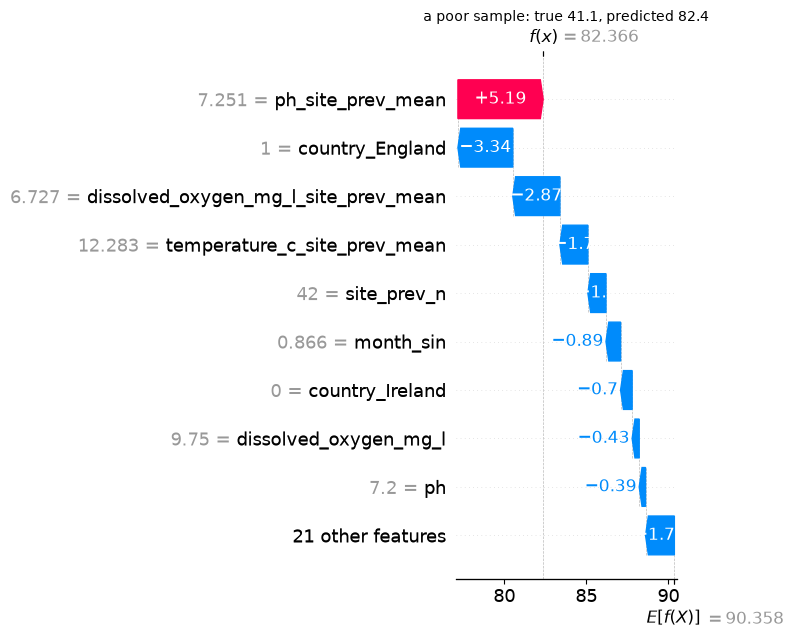

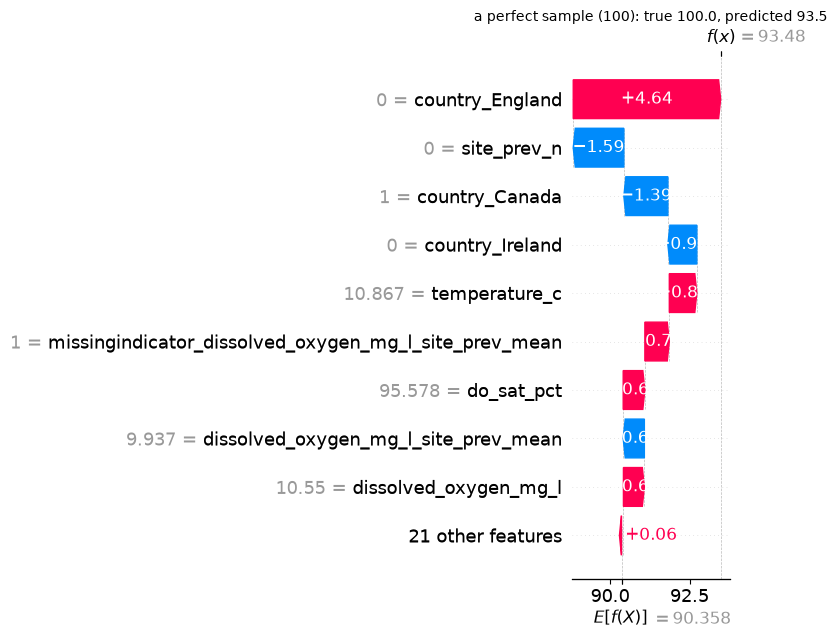

In [20]:
y_s = y_test.iloc[idx].to_numpy()
cases = {"a poor sample": int(np.argmin(y_s)), "a perfect sample (100)": int(np.argmax(y_s))}
for title, i in cases.items():
    exp = shap.Explanation(values=sv[i], base_values=base_value, data=Xt[i], feature_names=names)
    plt.figure()
    shap.plots.waterfall(exp, max_display=10, show=False)
    plt.title(f"{title}: true {y_s[i]:.1f}, predicted {base_value + sv[i].sum():.1f}", fontsize=10)
    save("shap_waterfall_" + ("poor" if "poor" in title else "perfect"))

**What we see → What we do about it:** For the poor sample, see whether the model recognised it (large negative pushes) or missed it (predicted near the average). That connects to the bias by quality level in section 5.3.

## 9. Summary for the report

The numbers below are filled in automatically from the results above, so the text always matches the tables. Copy them into the Results section.

In [22]:
b = best_name
rb, rz = final.loc[b], final.loc["Mean baseline"]
gain = 100 * (1 - rb["RMSE"] / rz["RMSE"])
d = paired[(paired["first"] == "XGBoost") & (paired["second"] == "Random Forest")].iloc[0]
worst_c, best_c = by_country["MAE gain vs baseline %"].idxmin(), by_country["MAE gain vs baseline %"].idxmax()

print(f"On the test set ({len(pb):,} rows from {S:,} stations the models never saw), {b} reached "
      f"R² = {rb['R2']:.3f} [{rb['R2 lo']:.3f}, {rb['R2 hi']:.3f}], RMSE = {rb['RMSE']:.2f} [{rb['RMSE lo']:.2f}, {rb['RMSE hi']:.2f}] "
      f"and MAE = {rb['MAE']:.2f} [{rb['MAE lo']:.2f}, {rb['MAE hi']:.2f}] (95% bootstrap intervals over stations).")
print(f"The mean-predictor baseline has RMSE {rz['RMSE']:.2f}, so the model lowers RMSE by {gain:.1f}%.")
print(f"XGBoost vs Random Forest: RMSE difference {d['RMSE difference (first - second)']:.3f} {d['95% interval']}, "
      f"clearly different: {d['clearly different?']}.")
print(f"Validation R² was {val_saved.loc[b, 'r2']:.3f}; test R² is {rb['R2']:.3f} (change {rb['R2'] - val_saved.loc[b, 'r2']:+.3f}).")
print(f"The model helps most in {best_c} ({by_country.loc[best_c, 'MAE gain vs baseline %']:.0f}% lower MAE than the baseline) "
      f"and least in {worst_c} ({by_country.loc[worst_c, 'MAE gain vs baseline %']:.0f}%).")
print(f"Bias: poor water (true < 60) is over-predicted by {by_band.loc['< 60 (poor)', 'bias']:+.1f} points on average.")
display(final.round(3))

On the test set (51,973 rows from 2,221 stations the models never saw), XGBoost reached R² = 0.293 [0.246, 0.340], RMSE = 11.06 [10.38, 11.82] and MAE = 7.54 [7.10, 8.04] (95% bootstrap intervals over stations).
The mean-predictor baseline has RMSE 13.16, so the model lowers RMSE by 16.0%.
XGBoost vs Random Forest: RMSE difference -0.121 [-0.186, -0.059], clearly different: yes.
Validation R² was 0.348; test R² is 0.293 (change -0.054).
The model helps most in Ireland (63% lower MAE than the baseline) and least in England (6%).
Bias: poor water (true < 60) is over-predicted by +31.0 points on average.


,MAE,MAE lo,MAE hi,RMSE,RMSE lo,RMSE hi,R2,R2 lo,R2 hi
model,,,,,,,,,
Mean baseline,9.570,9.070,10.134,13.159,12.376,13.996,-0.001,-0.009,-0.000
Ridge,8.329,7.883,8.820,11.733,11.067,12.428,0.205,0.174,0.233
Random Forest,7.598,7.157,8.094,11.179,10.513,11.935,0.278,0.230,0.324
XGBoost,7.543,7.103,8.041,11.058,10.384,11.816,0.293,0.246,0.340


### Limitations to state in the report
- **Moderate score by design.** The five parameters the index is calculated from are held out to avoid leakage, so only part of the index can be explained.
- **Country and station history carry much of the signal** (sections 7 and 8), so the model is partly learning "what is usual for this country or station".
- **Regression to the mean.** Poor water is over-predicted and the cap at 100 cannot be reached (section 5.3).
- **England dominates** the number of rows; small countries have wide uncertainty.
- **One tuning split.** Settings were chosen on a single validation split; two of the chosen settings sat at the edge of their search range.
- **XGBoost varies by about ±0.001 R²** between machines and library versions.
- **SHAP and importance show association, not cause.**